# 01 · Transfer to unseen groups: heating load for building geometries never simulated

A design team wants to know how much heating a new building will need before anyone runs an energy simulation for it. They have simulation results for earlier designs, and they want a model that turns those results into estimates for the new ones. The catch is that the new designs are built on building geometries that none of the earlier designs used.

That catch is the subject of this notebook. Many tables are made of groups, rows that share most of what determines the target: designs on one geometry, cells under one perturbation, patients at one hospital. A model can be excellent on new rows of a group it knows and still be far off on a group it has never seen, and an evaluation that mixes the two reports the easy answer. The lab's main application has exactly this shape, because a perturbation is a group of cells and the hard question is always a perturbation the model has not seen. This table is a small, fully known instance of the same problem, small enough that every number can be checked.

The notebook answers four questions in order:

1. **Which columns may the model use?** Only what a designer knows before simulating.
2. **How well does TabPFN transfer to three unseen geometries**, compared with untuned gradient boosting?
3. **Where are its errors?** Spread over all designs, or concentrated in particular geometries?
4. **Which decisions can its estimates support?** When is a predicted difference between two buildings larger than the model's error?

Notebook 02 then takes the group structure itself as the subject: how much of the table it explains, how to evaluate over all twelve geometries, and which models use the grouping directly.

## How TabPFN predicts

TabPFN is a transformer pretrained on millions of synthetic tables. It never updates its weights on your data. `fit` stores the labelled rows as *context*, and `predict` runs one forward pass over the context and the new rows together, inferring the relation between the columns and the target from the context in the same pass that applies it. There is no training loop and nothing to tune. For regression it returns a full predictive distribution over the target; the point estimate used below is that distribution's mean, and its quantiles give a prediction band.

## 1. Setup

`helper.py` in this folder holds the data loader, the split, the reference models and the plots. `init_tabpfn()` selects TabPFN-3.5, the lab's main model, when its license has been accepted, and TabPFN-2 otherwise, and keeps the model on the CPU on a Mac. The data are downloaded once into the shared data lake and checked against a fixed hash.

In [1]:
import time

import numpy as np
import pandas as pd

import helper
from helper import (
    DESIGN_COLUMNS,
    TARGET,
    errors_by_geometry,
    fit_predict_xgboost,
    geometry_names,
    geometry_table,
    grouped_split,
    load_energy_efficiency,
    plot_geometry_levels,
    plot_group_errors,
    plot_predicted_vs_actual,
    plot_predictive_quantiles,
    scores,
)

helper.configure_plots(plots=True)

from tabpfn import TabPFNRegressor
helper.init_tabpfn()

TabPFN v3.5 weights, running locally


'v3.5'

## 2. The table: a grid of design choices

The UCI Energy Efficiency data (Tsanas and Xifara, 2012, CC BY 4.0) hold 768 simulated residential buildings. Each design combines three choices:

- **a geometry**, described by five shape columns: relative compactness, surface area, wall area, roof area and overall height. All twelve geometries enclose the same volume, arranged differently: low and spread out, or tall and compact. Relative compactness measures how little outer surface a form has for that volume; a cube scores 1.0;
- **an orientation**, one of four compass directions coded 2 to 5;
- **a glazing setup**: no windows, or a window area of 10%, 25% or 40% of the floor area, spread over the facades in one of five patterns, which makes 16 setups.

The simulation then reports two outcomes per building, the heating load and the cooling load, in kWh per square metre. Every combination appears exactly once: 12 × 4 × 16 = 768. So each geometry is a group of 64 designs whose five shape columns are identical, and the helper numbers the geometries 0 to 11 in the order they first appear in the source workbook.

In [2]:
frame = load_energy_efficiency()
names = geometry_names(frame)
frame.head(3)

,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_distribution,heating_load,cooling_load,geometry
design_id,,,,,,,,,,,
E0001,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33,0
E0002,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33,0
E0003,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33,0


In [3]:
geometry_table(frame).assign(name=names)

,relative_compactness,surface_area,wall_area,roof_area,overall_height,designs,mean_heating_load,held_out,name
geometry,,,,,,,,,
0,0.98,514.5,294.0,110.25,7.0,64,27.646,False,0.98 / 7.0 m
1,0.90,563.5,318.5,122.50,7.0,64,31.629,False,0.90 / 7.0 m
2,0.86,588.0,294.0,147.00,7.0,64,28.553,True,0.86 / 7.0 m
3,0.82,612.5,318.5,147.00,7.0,64,25.555,False,0.82 / 7.0 m
4,0.79,637.0,343.0,147.00,7.0,64,38.608,False,0.79 / 7.0 m
5,0.76,661.5,416.5,122.50,7.0,64,35.664,False,0.76 / 7.0 m
6,0.74,686.0,245.0,220.50,3.5,64,11.887,True,0.74 / 3.5 m
7,0.71,710.5,269.5,220.50,3.5,64,12.040,False,0.71 / 3.5 m
8,0.69,735.0,294.0,220.50,3.5,64,12.389,False,0.69 / 3.5 m


Two things stand out in the table. Overall height takes only two values, 3.5 m and 7.0 m, which we will call one and two storeys. And it separates heating loads sharply: the one-storey geometries average 12 to 17, the two-storey ones 26 to 39. The figure shows every design, one column per geometry, ordered by compactness within each height; orange marks the three geometries this notebook holds out.

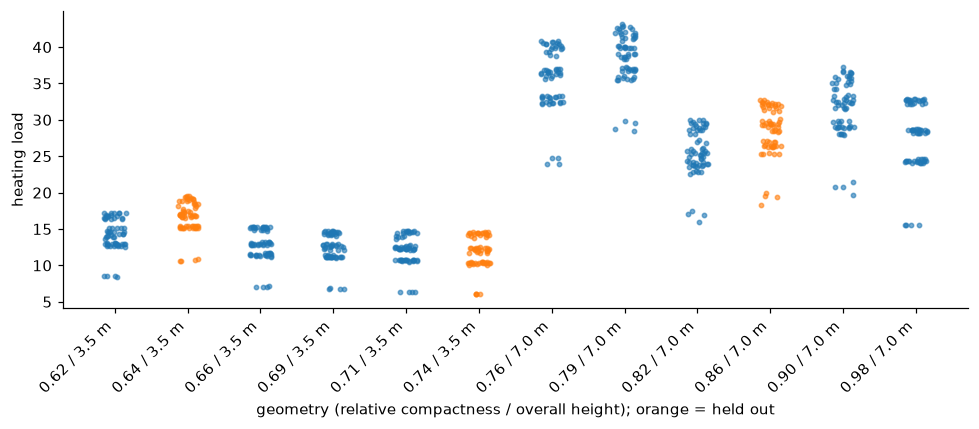

In [4]:
plot_geometry_levels(frame)

Within each column, the spread comes from glazing and orientation; between columns, from geometry. The columns are far apart compared with their own height, which is the visual form of the claim notebook 02 quantifies: most of what decides a building's heating load is which geometry it has.

## 3. Choosing the inputs

The rule is simple: an input must be known at the moment of prediction, which here is before the simulation runs.

- **Heating load** is the target.
- **Cooling load** is excluded. It is a second outcome of the same simulation, so a design that has not been simulated does not have it. It would be a powerful input, because it moves almost in lockstep with the target, and that is exactly the problem: a model trained on it would look excellent on history and have nothing to use for a new design.
- **The design identifier** is a key for matching rows. It describes nothing about the building, and in this table it only encodes the order of the source rows.
- **The eight design columns** are all set by the designer, so all eight are admissible.

In [5]:
print(f"correlation of heating and cooling load: {frame[TARGET].corr(frame['cooling_load']):.3f}")

correlation of heating and cooling load: 0.976


Admissible is not the same as useful, and two of the eight deserve a look. Several shape columns describe the same geometry in overlapping ways, and orientation may not matter at all.

In [6]:
gap = (frame["surface_area"] - (frame["wall_area"] + 2 * frame["roof_area"])).abs().max()
print(f"largest |surface area - (wall area + 2 x roof area)|: {gap}")
print(f"correlation of compactness and surface area: {frame['relative_compactness'].corr(frame['surface_area']):.3f}")
frame.groupby("orientation")[TARGET].mean().round(2).rename("mean heating load by orientation")

largest |surface area - (wall area + 2 x roof area)|: 0.0
correlation of compactness and surface area: -0.992


orientation
2    22.31
3    22.38
4    22.26
5    22.28
Name: mean heating load by orientation, dtype: float64

Surface area is exactly wall area plus twice the roof area, compactness falls almost one-for-one as surface area rises, and the mean heating load barely moves with orientation. Section 8 tests whether removing the redundant pair changes anything. The first run keeps all eight columns, because each is legitimately available and the model can learn to ignore what does not help.

## 4. The split: three geometries held out

The split holds out whole geometries, not random designs. Geometries 2, 6 and 10 go to the test side, 192 designs; the other nine geometries, 576 designs, are the context. A random split would put designs of every geometry on both sides, so the model could learn each geometry's level from its siblings; holding out whole geometries asks the realistic question instead, a building form nobody has simulated yet.

The three roles:

| Role | Rows | What it holds | How it is used |
|---|---|---|---|
| `history` | 576 designs, 9 geometries | design columns and both simulated outcomes | the context TabPFN is fitted on |
| `current` | 192 designs, 3 geometries | design columns only | the designs to predict |
| `answers` | the same 192 designs | true heating load | scoring, after prediction |

In [7]:
history, current, answers = grouped_split(frame)
print(f"context: {len(history)} designs from {history['geometry'].nunique()} geometries")
held_out = sorted(int(g) for g in current["geometry"].unique())
print(f"to predict: {len(current)} designs from geometries {held_out}: " + ", ".join(names[g] for g in held_out))
print(f"wall area in the context: {history['wall_area'].min()} to {history['wall_area'].max()}; "
      f"held-out geometry 6 has {current.loc[current['geometry'] == 6, 'wall_area'].iloc[0]}")

context: 576 designs from 9 geometries
to predict: 192 designs from geometries [2, 6, 10]: 0.86 / 7.0 m, 0.74 / 3.5 m, 0.64 / 3.5 m
wall area in the context: 269.5 to 416.5; held-out geometry 6 has 245.0


Two of the held-out geometries lie inside the range the context covers. The third, compactness 0.74, has a wall area below every context geometry, so the model has to go slightly beyond what it has seen.

## 5. Fit on the context, predict the new designs

The two calls are the whole workflow. `fit` receives the context's eight design columns and its heating loads, nothing else; `predict` receives the new designs' eight columns, in the same order, and returns one estimate per row in the order the rows came in. First a single design, then all 192. With `output_type="main"` the batch call also returns the predictive quantiles.

In [8]:
FEATURES = DESIGN_COLUMNS

start = time.perf_counter()
model = TabPFNRegressor(random_state=0)
model.fit(history[FEATURES], history[TARGET])
batch = model.predict(current[FEATURES], output_type="main")
tabpfn_seconds = time.perf_counter() - start

single = model.predict(current.loc[["E0505"], FEATURES])
print(f"E0505: estimate {single[0]:.2f}, true {answers['E0505']:.2f}")

tabpfn_mean = pd.Series(batch["mean"], index=current.index)
quantiles = np.asarray(batch["quantiles"])
print(f"{len(tabpfn_mean)} estimates, fit and predict in {tabpfn_seconds:.1f} s")

E0505: estimate 12.29, true 12.12
192 estimates, fit and predict in 18.1 s


`E0505` is a one-storey design on the out-of-range geometry, with 25% glazing. Its estimate is within a fraction of a unit of the truth. The predictive distribution says more than the point estimate: its middle 80% spans several units, which is TabPFN saying it is not sure where this new geometry's level sits.

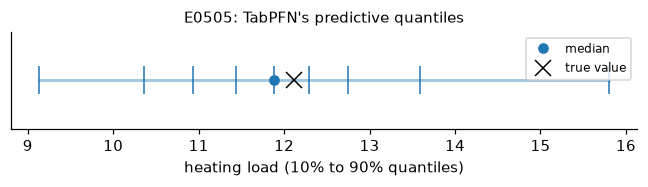

In [9]:
column = current.index.get_loc("E0505")
plot_predictive_quantiles(quantiles[:, column], answers["E0505"], "E0505: TabPFN's predictive quantiles")

## 6. Against a reference: XGBoost

The reference is XGBoost with its default settings, trained on the same 576 designs and the same eight columns. Default settings are the fair comparison for an untuned TabPFN.

In [10]:
xgb = fit_predict_xgboost(history, current, FEATURES)
headline = pd.DataFrame(
    {
        "TabPFN": {**scores(answers, tabpfn_mean), "seconds": tabpfn_seconds},
        "XGBoost": {**scores(answers, xgb["mean"]), "seconds": xgb["seconds"]},
    }
).T
print(f"TabPFN MAE over the 192 designs: {headline.loc['TabPFN', 'mae']:.6f}")
headline

TabPFN MAE over the 192 designs: 0.873092


,mae,r2,signed,seconds
TabPFN,0.873,0.979,-0.521,18.084
XGBoost,1.904,0.908,-1.725,0.025


TabPFN's typical error is less than half of XGBoost's, and it explains about 98% of the variance in the held-out heating loads against about 91%. For scale, those heating loads run from about 6 to 33. XGBoost is several hundred times faster on a laptop CPU; both are fast enough for 192 designs. Both models also err low on average (the `signed` column, prediction minus truth), XGBoost by more.

The plot shows each model's predictions against the truth, coloured by geometry. Within a colour, the points form a line roughly parallel to the diagonal; the gap between that line and the diagonal is the subject of the next section.

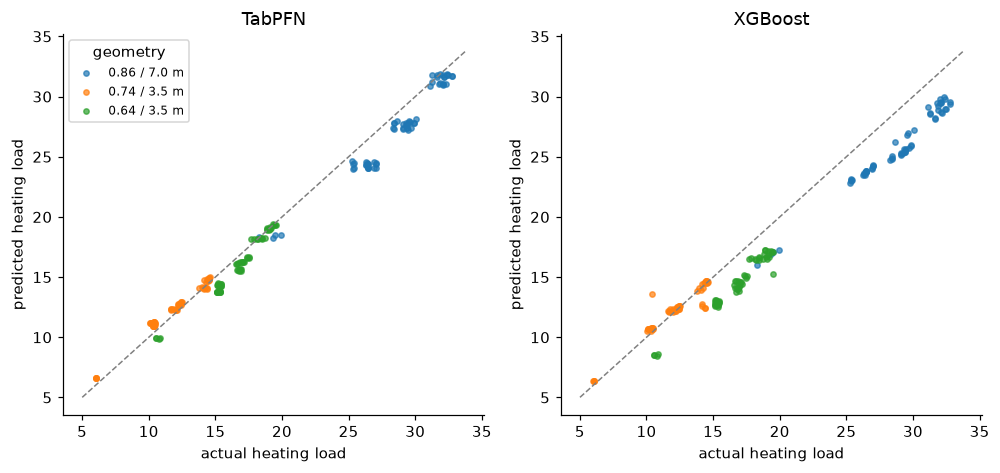

In [11]:
plot_predicted_vs_actual(answers, {"TabPFN": tabpfn_mean, "XGBoost": xgb["mean"]}, current["geometry"], names)

## 7. Where the errors are

A single MAE over 192 designs hides where the error comes from. Splitting it by geometry, and setting the MAE beside the mean signed error, separates two kinds of error: scatter, where predictions miss in both directions, and a shared offset, where a model misses every design of a geometry by about the same amount in the same direction. When a geometry's MAE is about the size of its mean signed error, the error is an offset.

In [12]:
by_geometry = errors_by_geometry(current["geometry"], answers, {"TabPFN": tabpfn_mean, "XGBoost": xgb["mean"]})
by_geometry.rename(index=names.to_dict())

TabPFN        XGBoost       
                MAE signed     MAE signed
geometry                                 
0.86 / 7.0 m  1.356 -1.335   2.997 -2.997
0.74 / 3.5 m  0.512  0.482   0.384  0.154
0.64 / 3.5 m  0.751 -0.711   2.331 -2.331

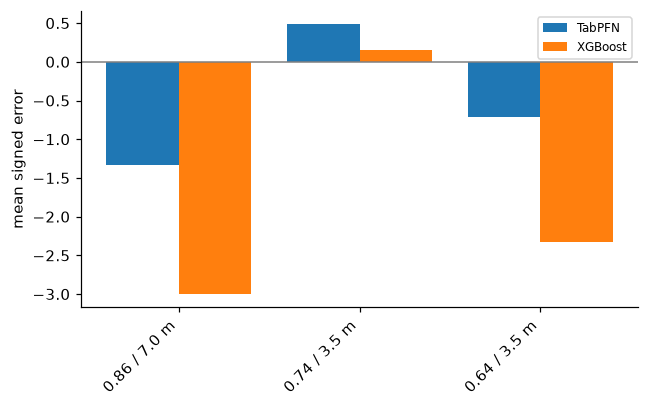

In [13]:
plot_group_errors(by_geometry, names, metric="signed")

Three findings:

- **The error is almost entirely an offset per geometry.** For each geometry and each model, the MAE nearly equals the size of the mean signed error. A model that has never seen a geometry has to guess where its overall level sits, and whatever it gets wrong there, every one of the 64 designs inherits.
- **The hardest geometry is not the out-of-range one.** The compactness 0.74 geometry, whose wall area lies outside the context, has the smallest errors, and there XGBoost is even slightly better than TabPFN. The hardest is the two-storey 0.86 geometry, which both models predict too low, XGBoost by more than twice as much.
- **Range matters less than smoothness.** The table below lists the two-storey context geometries. The held-out 0.86 lies between 0.82 and 0.90, but the heating level does not change smoothly with compactness among tall buildings: it jumps from about 39 at 0.79 to about 26 at 0.82, then rises again. The one-storey levels, by contrast, sit in a narrow, calm band, so even a small step outside their range is safe.

In [14]:
table = geometry_table(frame)
table.loc[table["overall_height"] == 7.0, ["relative_compactness", "wall_area", "roof_area", "mean_heating_load", "held_out"]]

,relative_compactness,wall_area,roof_area,mean_heating_load,held_out
geometry,,,,,
0,0.98,294.0,110.25,27.646,False
1,0.90,318.5,122.50,31.629,False
2,0.86,294.0,147.00,28.553,True
3,0.82,318.5,147.00,25.555,False
4,0.79,343.0,147.00,38.608,False
5,0.76,416.5,122.50,35.664,False


## 8. What the estimates can decide

A design team does not need heating loads for their own sake; they need to choose between designs. The useful question is whether a predicted difference between two buildings is large compared with the model's typical error. Two pairs show both outcomes:

- `E0009` and `E0010` differ only in orientation: same two-storey 0.86 geometry, no windows.
- `E0009` and `E0249` share that geometry, but `E0249` has 10% glazing.

In [15]:
def compare(a, b):
    return {
        "TabPFN gap": tabpfn_mean[b] - tabpfn_mean[a],
        "XGBoost gap": xgb["mean"][current.index.get_loc(b)] - xgb["mean"][current.index.get_loc(a)],
        "true gap": answers[b] - answers[a],
    }

pd.DataFrame({"E0009 to E0010 (orientation)": compare("E0009", "E0010"),
              "E0009 to E0249 (glazing)": compare("E0009", "E0249")}).T.round(2)

,TabPFN gap,XGBoost gap,true gap
E0009 to E0010 (orientation),0.00,0.22,0.45
E0009 to E0249 (glazing),5.59,7.27,7.53


For the orientation pair, TabPFN's predicted gap is essentially zero, far below its typical error of under one unit: it cannot say which of the two needs more heat. For the glazing pair the predicted gap is several times the typical error, so the ranking is safe, though TabPFN understates the gap by about a quarter. XGBoost's gap for this pair is closer to the truth, even though its overall error is twice TabPFN's: both designs carry the same large offset for this geometry, and a gap between two designs of one geometry cancels it.

The orientation result is general, not a feature of one pair. Among designs that are identical except for orientation, the true heating loads spread over about 0.6 units on average, while TabPFN's estimates spread over less than 0.1. In the context, orientation shows no consistent effect, so the model has learned to treat it as irrelevant.

In [16]:
spread = current.assign(estimate=tabpfn_mean, truth=answers).groupby(["geometry", "glazing_area", "glazing_distribution"])
print(f"mean spread across orientations: estimates {spread['estimate'].agg(np.ptp).mean():.2f}, "
      f"truth {spread['truth'].agg(np.ptp).mean():.2f}")

mean spread across orientations: estimates 0.09, truth 0.61


The estimates therefore support decisions driven by glazing or by geometry, where predicted gaps are several times the error, and not decisions driven by orientation alone. One more consequence of the offset pattern: two designs on the same geometry share most of that geometry's offset, so comparing them is more reliable than the overall MAE suggests, while two designs on different geometries carry both offsets.

## 9. A second input set

Section 3 left two columns in question: surface area, which adds no information, and orientation, which the model ignores. Removing both should cost nothing if TabPFN, like a tree ensemble, is indifferent to redundant inputs. That is the test.

In [17]:
TRIMMED = [c for c in DESIGN_COLUMNS if c not in ("surface_area", "orientation")]

trimmed_model = TabPFNRegressor(random_state=0)
trimmed_model.fit(history[TRIMMED], history[TARGET])
tabpfn_trimmed = pd.Series(trimmed_model.predict(current[TRIMMED]), index=current.index)
xgb_trimmed = fit_predict_xgboost(history, current, TRIMMED)

pd.DataFrame(
    {
        "TabPFN, eight columns": scores(answers, tabpfn_mean),
        "TabPFN, six columns": scores(answers, tabpfn_trimmed),
        "XGBoost, eight columns": scores(answers, xgb["mean"]),
        "XGBoost, six columns": scores(answers, xgb_trimmed["mean"]),
    }
).T

,mae,r2,signed
"TabPFN, eight columns",0.873,0.979,-0.521
"TabPFN, six columns",1.033,0.973,-0.074
"XGBoost, eight columns",1.904,0.908,-1.725
"XGBoost, six columns",1.908,0.908,-1.726


In [18]:
errors_by_geometry(current["geometry"], answers,
                   {"TabPFN, eight": tabpfn_mean, "TabPFN, six": tabpfn_trimmed}).rename(index=names.to_dict())

TabPFN, eight        TabPFN, six       
                       MAE signed         MAE signed
geometry                                            
0.86 / 7.0 m         1.356 -1.335       1.530 -1.518
0.74 / 3.5 m         0.512  0.482       0.984  0.984
0.64 / 3.5 m         0.751 -0.711       0.584  0.311

XGBoost does not notice the change: a tree splits on one column at a time and had already ignored both. TabPFN does notice. In this run its MAE rises, it improves on one geometry and loses on the other two, and the two-storey shortfall grows slightly rather than shrinking. An in-context learner reads the whole row at once, so how the inputs describe a building is part of what it conditions on, even when a column adds no information.

How large the effect is, this run cannot say. TabPFN averages an ensemble of internal passes whose randomness is set by `random_state`, and over three seeds the [results page](docs/results/01-unseen-geometry-transfer.md) finds the eight-column MAE anywhere from 0.86 to 1.11. The six-column set is worse on average over those seeds, but not in every one; the honest summary is that removing the redundant pair did not help, and that differences of this size need several seeds before they mean anything.

## What this leaves open

- **Three geometries are three tests.** Every geometry-level statement above rests on three groups of 64 designs. Notebook 02 holds out each of the twelve geometries in turn.
- **The offset is the error.** Since the miss is a shift per geometry, a model that represents the grouping explicitly, separating a geometry's level from the effects inside it, might do better or at least say honestly how uncertain a new geometry is. Notebook 02 fits a mixed-effects model and a two-stage model as references.
- **The predictive band is wide.** TabPFN's 80% band covered every held-out design here (section 5 shows one). Whether that is calibrated caution or simply width is a question for twelve geometries, not three.

The [results page](docs/results/01-unseen-geometry-transfer.md) repeats this notebook's split with three seeds and both TabPFN versions, generated by `01_unseen_geometry_transfer_report.py`.